Full dataset shape: (3288, 15)
Care groups found:  <StringArray>
['ERWACHSENE', 'NICU', 'PICU']
Length: 3, dtype: str
Date range:         2023-02-10 → 2026-02-09

PICU rows after filtering: 1096
Date range (PICU):         2023-02-10 → 2026-02-09

Rows used for clustering (no NaNs): 1096

Feature summary:
       utilization_rate  slack_rate  staff_rate  material_rate  space_rate
count         1096.0000   1096.0000   1096.0000      1096.0000   1096.0000
mean             0.6364      0.3636      0.2628         0.0033      0.0927
std              0.0466      0.0466      0.0665         0.0042      0.0337
min              0.5300      0.2200      0.1491         0.0000      0.0172
25%              0.6000      0.3300      0.2082         0.0000      0.0672
50%              0.6300      0.3700      0.2500         0.0000      0.0870
75%              0.6700      0.4000      0.3122         0.0069      0.1135
max              0.7800      0.4700      0.4286         0.0145      0.2000

──────────────────

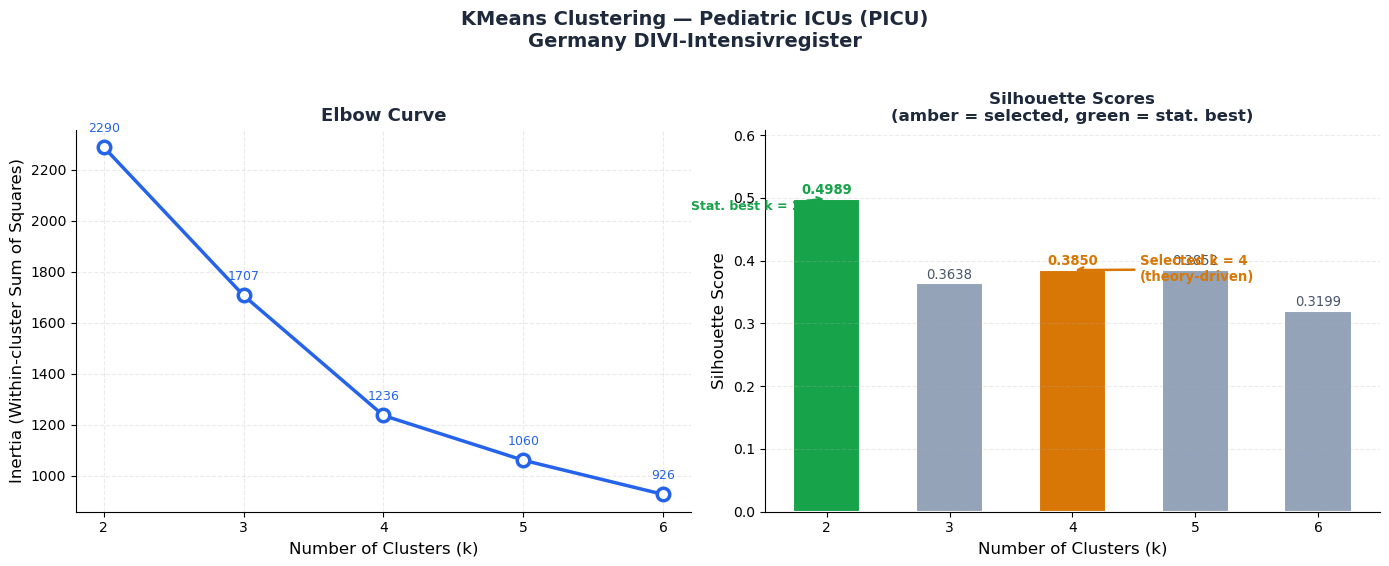


✅ Refitted KMeans with k = 4 (theoretically motivated)
   Cluster sizes:
cluster
0    270
1    243
2    172
3    411

────────────────────────────────────────────────────────────
📋 Cluster profile (mean feature values) — k = 4
────────────────────────────────────────────────────────────
         utilization_rate  slack_rate  staff_rate  material_rate  space_rate
cluster                                                                     
0                  0.6470      0.3530      0.3179         0.0071      0.1080
1                  0.6507      0.3493      0.2336         0.0000      0.0837
2                  0.7092      0.2908      0.3526         0.0094      0.1435
3                  0.5905      0.4095      0.2062         0.0001      0.0666

────────────────────────────────────────────────────────────
🏷️  Regime names assigned:
────────────────────────────────────────────────────────────
  Cluster 0 → Moderate-Strain Regime  (n = 270)
  Cluster 1 → Low-Strain Regime  (n = 243)
  Cluste

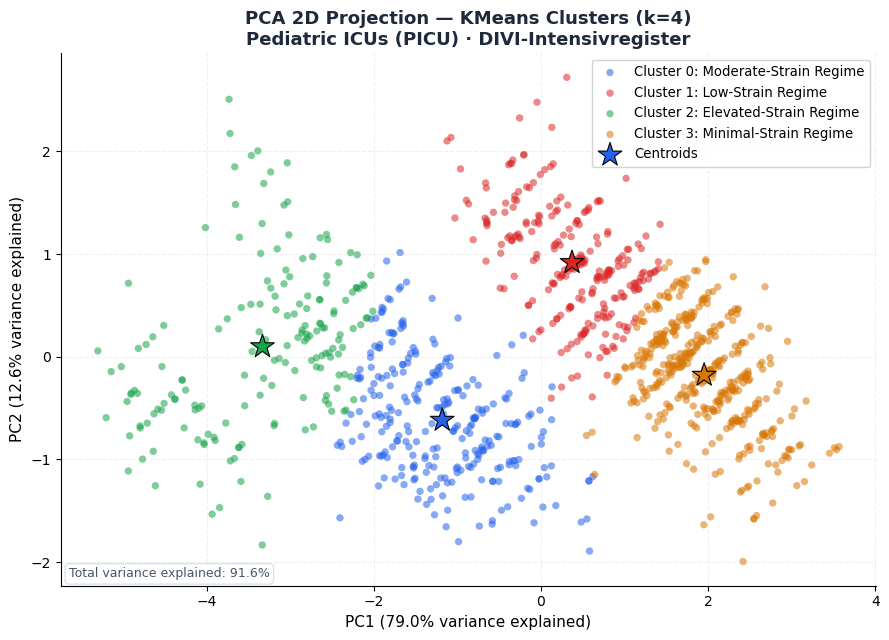

💾 Clustered dataset saved → picu_clustered.csv

────────────────────────────────────────────────────────────
✅ All done.
────────────────────────────────────────────────────────────


In [3]:
"""
KMeans Clustering Analysis — Pediatric ICUs (PICU)
Germany DIVI-Intensivregister
Thesis: Mapping ICU Capacity Strain in Germany — Sarah Busch

This script:
1.  Loads and cleans the DIVI dataset
2.  Filters to PICUs only (no date restriction)
3.  Engineers constraint rate features
4.  Runs KMeans for k=2 to k=6
5.  Computes inertia (elbow) and silhouette scores
6.  Plots elbow curve + silhouette bar chart
7.  Sets k=4 (theoretically motivated)
8.  Refits KMeans with k=4 and assigns cluster labels
9.  Profiles each cluster (mean feature values) and names regimes
10. Robustness check: re-runs with k±1 and compares silhouette scores
11. Robustness check: Agglomerative Clustering with same k + ARI comparison
12. PCA 2D scatter plot with colour-coded cluster labels
"""

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────
# 1. LOAD & CLEAN
# ─────────────────────────────────────────

# Update this path to wherever your CSV lives
DATA_PATH = "Intensivregister_updated.csv"

df = pd.read_csv(DATA_PATH, sep=';', encoding='utf-8-sig')

# Strip whitespace from column names
df.columns = df.columns.str.strip()

# Convert European-style decimals (commas → dots) and cast to float
for col in df.columns:
    if col not in ['date', 'care_group']:
        df[col] = (
            df[col].astype(str)
                   .str.replace(',', '.', regex=False)
                   .str.strip()
        )
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Parse dates (day-first format: DD/MM/YYYY)
df['date'] = pd.to_datetime(df['date'], dayfirst=True)

print(f"Full dataset shape: {df.shape}")
print(f"Care groups found:  {df['care_group'].unique()}")
print(f"Date range:         {df['date'].min().date()} → {df['date'].max().date()}")

# ─────────────────────────────────────────
# 2. FILTER: PICU only (no date restriction)
# ─────────────────────────────────────────

picu = df[
    df['care_group'] == 'PICU'
].copy()

# Drop COVID-related columns (per proposal)
covid_cols = [c for c in picu.columns if 'covid' in c.lower()]
picu = picu.drop(columns=covid_cols, errors='ignore')

print(f"\nPICU rows after filtering: {len(picu)}")
print(f"Date range (PICU):         {picu['date'].min().date()} → {picu['date'].max().date()}")

# ─────────────────────────────────────────
# 3. FEATURE ENGINEERING (per proposal)
#    Rates = constraint count / reporting units
# ─────────────────────────────────────────

picu['staff_rate']    = picu['staff_constraints']    / picu['reporting_units']
picu['space_rate']    = picu['space_constraints']    / picu['reporting_units']
picu['material_rate'] = picu['material_constraints'] / picu['reporting_units']

# Clustering features: utilization, slack, three constraint rates
features = [
    'utilization_rate',
    'slack_rate',
    'staff_rate',
    'material_rate',
    'space_rate'
]

X = picu[features].dropna()
print(f"\nRows used for clustering (no NaNs): {len(X)}")
print("\nFeature summary:")
print(X.describe().round(4))

# ─────────────────────────────────────────
# 4. STANDARDISE
# ─────────────────────────────────────────

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ─────────────────────────────────────────
# 5. KMEANS: k = 2 → 6
# ─────────────────────────────────────────

k_range     = range(2, 7)
inertias    = []
silhouettes = []
all_labels  = {}

print("\n" + "─"*50)
print(f"{'k':>3}  {'Inertia':>12}  {'Silhouette':>12}")
print("─"*50)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20, max_iter=500)
    labels = km.fit_predict(X_scaled)
    inertia = km.inertia_
    sil     = silhouette_score(X_scaled, labels)

    inertias.append(inertia)
    silhouettes.append(sil)
    all_labels[k] = labels

    print(f"{k:>3}  {inertia:>12.2f}  {sil:>12.4f}")

print("─"*50)

# ─────────────────────────────────────────
# 6. SET K = 4 (THEORETICALLY MOTIVATED)
# ─────────────────────────────────────────

# While silhouette scores may favour a lower k statistically, k=4 is chosen
# on theoretical grounds aligned with capacity strain theory and the thesis
# research questions. A binary partition (k=2) cannot distinguish between
# qualitatively different types of strain (e.g. demand-driven vs. resource-
# constrained vs. multi-bottleneck regimes). k=4 allows for four distinct
# operational stress regimes such as:
#   (1) Low-strain baseline — low utilization, few constraints
#   (2) Demand-driven strain — high utilization, primarily staff-constrained
#   (3) Multi-constrained — simultaneous staff + space + material pressure
#   (4) Structural bottleneck — space/material constrained without peak demand
# This mapping directly supports H1 (constraint co-occurrence), H2 (utilization
# differences across regimes), and generates actionable operational insights.
# Robustness checks (k±1 ARI, Agglomerative ARI) validate partition stability.
# Note: PICUs serve pediatric patients and differ from adult ICUs in staffing
# norms, bed ratios, and care intensity — regime patterns may reflect these
# structural differences and should be interpreted in that clinical context.

optimal_k   = 4
stat_best_k = list(k_range)[silhouettes.index(max(silhouettes))]
print(f"\n📌 Statistically optimal k (highest silhouette): k = {stat_best_k}  |  score = {max(silhouettes):.4f}")
print(f"✅ Selected k = {optimal_k} (theoretically motivated)  |  silhouette = {silhouettes[list(k_range).index(optimal_k)]:.4f}")

# ─────────────────────────────────────────
# 7. PLOT: Elbow + Silhouette side by side
# ─────────────────────────────────────────

k_list = list(k_range)
BLUE   = '#2563EB'
GREEN  = '#16a34a'
GREY   = '#94a3b8'
DARK   = '#1e293b'

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle(
    'KMeans Clustering — Pediatric ICUs (PICU)\nGermany DIVI-Intensivregister',
    fontsize=14, fontweight='bold', color=DARK, y=1.02
)

# ── Left: Elbow curve ──
ax1 = axes[0]
ax1.plot(k_list, inertias, 'o-', color=BLUE, linewidth=2.5,
         markersize=9, markerfacecolor='white', markeredgewidth=2.5)
for k, iner in zip(k_list, inertias):
    ax1.annotate(f'{iner:.0f}', (k, iner),
                 textcoords='offset points', xytext=(0, 11),
                 ha='center', fontsize=9, color=BLUE)
ax1.set_xlabel('Number of Clusters (k)', fontsize=12)
ax1.set_ylabel('Inertia (Within-cluster Sum of Squares)', fontsize=12)
ax1.set_title('Elbow Curve', fontsize=13, fontweight='bold', color=DARK)
ax1.set_xticks(k_list)
ax1.grid(True, alpha=0.25, linestyle='--')
ax1.spines[['top', 'right']].set_visible(False)

# ── Right: Silhouette bar chart ──
ax2 = axes[1]
bar_colors = []
for i, (k, s) in enumerate(zip(k_list, silhouettes)):
    if k == optimal_k:
        bar_colors.append('#d97706')   # amber = theoretically chosen
    elif s == max(silhouettes):
        bar_colors.append(GREEN)       # green = statistically best
    else:
        bar_colors.append(GREY)
bars = ax2.bar(k_list, silhouettes, color=bar_colors,
               edgecolor='white', linewidth=1.5, width=0.55)
for k, sil, bar in zip(k_list, silhouettes, bars):
    is_chosen = (k == optimal_k)
    is_best   = (sil == max(silhouettes))
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.003,
        f'{sil:.4f}',
        ha='center', va='bottom',
        fontsize=9.5,
        fontweight='bold' if (is_chosen or is_best) else 'normal',
        color='#d97706' if is_chosen else (GREEN if is_best else '#475569')
    )

# Annotate chosen k=4
ax2.annotate(
    f'Selected k = {optimal_k}\n(theory-driven)',
    xy=(optimal_k, silhouettes[list(k_range).index(optimal_k)]),
    xytext=(optimal_k + 0.55, silhouettes[list(k_range).index(optimal_k)] - 0.018),
    fontsize=9.5, color='#d97706', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#d97706', lw=1.8)
)
# Also annotate statistical best if different from chosen k
if stat_best_k != optimal_k:
    ax2.annotate(
        f'Stat. best k = {stat_best_k}',
        xy=(stat_best_k, max(silhouettes)),
        xytext=(stat_best_k - 1.1, max(silhouettes) - 0.018),
        fontsize=9, color=GREEN, fontweight='bold',
        arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.5)
    )

ax2.set_xlabel('Number of Clusters (k)', fontsize=12)
ax2.set_ylabel('Silhouette Score', fontsize=12)
ax2.set_title('Silhouette Scores\n(amber = selected, green = stat. best)', fontsize=12, fontweight='bold', color=DARK)
ax2.set_xticks(k_list)
ax2.set_ylim(0, max(silhouettes) * 1.22)
ax2.grid(True, alpha=0.25, linestyle='--', axis='y')
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

output_fig = "kmeans_elbow_silhouette_picu.png"
plt.savefig(output_fig, dpi=180, bbox_inches='tight')
print(f"\n📊 Plot saved → {output_fig}")
plt.show()

# ─────────────────────────────────────────
# 8. REFIT WITH K=4 & ASSIGN LABELS
# ─────────────────────────────────────────

km_final     = KMeans(n_clusters=optimal_k, random_state=42, n_init=20, max_iter=500)
final_labels = km_final.fit_predict(X_scaled)

X = X.copy()
X['cluster']          = final_labels
picu_clustered        = picu.loc[X.index].copy()
picu_clustered['cluster'] = final_labels

print(f"\n✅ Refitted KMeans with k = {optimal_k} (theoretically motivated)")
print(f"   Cluster sizes:\n{picu_clustered['cluster'].value_counts().sort_index().to_string()}")

# ─────────────────────────────────────────
# 9. CLUSTER PROFILING & REGIME NAMING
# ─────────────────────────────────────────

profile = picu_clustered.groupby('cluster')[features].mean().round(4)

print(f"\n{'─'*60}")
print(f"📋 Cluster profile (mean feature values) — k = {optimal_k}")
print(f"{'─'*60}")
print(profile.to_string())

# ── Auto-name regimes based on combined strain score ──
profile['strain_score'] = profile['staff_rate'] + profile['utilization_rate'] + profile['space_rate']
strain_order = profile['strain_score'].rank().astype(int)

regime_names = {}
n = optimal_k
for cluster_id, rank in strain_order.items():
    if n == 2:
        regime_names[cluster_id] = 'Low-Strain Regime' if rank == 1 else 'High-Strain Regime'
    elif n == 3:
        mapping = {1: 'Low-Strain Regime', 2: 'Moderate-Strain Regime', 3: 'High-Strain Regime'}
        regime_names[cluster_id] = mapping[rank]
    else:
        ordinals = {1: 'Minimal', 2: 'Low', 3: 'Moderate', 4: 'Elevated', 5: 'High', 6: 'Severe'}
        regime_names[cluster_id] = f"{ordinals.get(rank, str(rank))}-Strain Regime"

profile = profile.drop(columns='strain_score')
picu_clustered['regime'] = picu_clustered['cluster'].map(regime_names)

print(f"\n{'─'*60}")
print("🏷️  Regime names assigned:")
print(f"{'─'*60}")
for cid, name in regime_names.items():
    size = (picu_clustered['cluster'] == cid).sum()
    print(f"  Cluster {cid} → {name}  (n = {size})")

print(f"\n{'─'*60}")
print("📊 Full profile with regime names:")
print(f"{'─'*60}")
profile_named = profile.copy()
profile_named.index = [regime_names[i] for i in profile_named.index]
print(profile_named.to_string())

# ─────────────────────────────────────────
# 10. ROBUSTNESS CHECK A: k±1
# ─────────────────────────────────────────

print(f"\n{'─'*60}")
print(f"🔁 Robustness Check A — KMeans with k±1")
print(f"{'─'*60}")

robustness_results = {}
for k_alt in [optimal_k - 1, optimal_k, optimal_k + 1]:
    if k_alt < 2:
        continue
    km_alt     = KMeans(n_clusters=k_alt, random_state=42, n_init=20, max_iter=500)
    labels_alt = km_alt.fit_predict(X_scaled)
    sil_alt    = silhouette_score(X_scaled, labels_alt)
    ari_alt    = adjusted_rand_score(final_labels, labels_alt) if k_alt != optimal_k else 1.0
    robustness_results[k_alt] = {'silhouette': sil_alt, 'ARI_vs_optimal': ari_alt}
    marker = " ← selected" if k_alt == optimal_k else ""
    print(f"  k={k_alt}: Silhouette = {sil_alt:.4f}  |  ARI vs k={optimal_k} = {ari_alt:.4f}{marker}")

print("\n  ℹ️  ARI (Adjusted Rand Index): 1.0 = identical assignments, 0 = random.")
print(f"  A high ARI for k±1 vs k={optimal_k} confirms the partition is stable.")

# ─────────────────────────────────────────
# 11. ROBUSTNESS CHECK B: Agglomerative Clustering
# ─────────────────────────────────────────

print(f"\n{'─'*60}")
print(f"🔁 Robustness Check B — Agglomerative Clustering (k = {optimal_k})")
print(f"{'─'*60}")

agg        = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)

sil_agg = silhouette_score(X_scaled, agg_labels)
ari_agg = adjusted_rand_score(final_labels, agg_labels)

print(f"  Agglomerative Silhouette : {sil_agg:.4f}")
print(f"  KMeans      Silhouette   : {silhouettes[list(k_range).index(optimal_k)]:.4f}")
print(f"  ARI (KMeans vs Agglom.)  : {ari_agg:.4f}")
print(f"\n  ℹ️  ARI ≥ 0.80 → strong agreement between methods (robust partition).")
print(f"       ARI ≥ 0.60 → moderate agreement (interpretations likely stable).")
print(f"       ARI < 0.60 → divergence — treat cluster boundaries with caution.")

# ─────────────────────────────────────────
# 12. PCA 2D SCATTER PLOT
# ─────────────────────────────────────────

pca           = PCA(n_components=2, random_state=42)
X_pca         = pca.fit_transform(X_scaled)
var_explained = pca.explained_variance_ratio_ * 100

PALETTE = ['#2563EB', '#dc2626', '#16a34a', '#d97706', '#7c3aed', '#0891b2']

fig2, ax = plt.subplots(figsize=(9, 6.5))

for cid in sorted(picu_clustered['cluster'].unique()):
    mask = picu_clustered['cluster'].values == cid
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=PALETTE[cid], label=f"Cluster {cid}: {regime_names[cid]}",
        alpha=0.55, s=28, edgecolors='none'
    )

# Plot KMeans centroids projected into PCA space
centroids_pca = pca.transform(km_final.cluster_centers_)
ax.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c=[PALETTE[i] for i in range(optimal_k)],
    marker='*', s=320, edgecolors='black', linewidths=0.8,
    zorder=5, label='Centroids'
)

ax.set_xlabel(f'PC1 ({var_explained[0]:.1f}% variance explained)', fontsize=11)
ax.set_ylabel(f'PC2 ({var_explained[1]:.1f}% variance explained)', fontsize=11)
ax.set_title(
    f'PCA 2D Projection — KMeans Clusters (k={optimal_k})\n'
    f'Pediatric ICUs (PICU) · DIVI-Intensivregister',
    fontsize=13, fontweight='bold', color=DARK
)
ax.legend(fontsize=9.5, framealpha=0.85, loc='best')
ax.grid(True, alpha=0.2, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)

ax.text(
    0.01, 0.01,
    f'Total variance explained: {sum(var_explained):.1f}%',
    transform=ax.transAxes, fontsize=9, color='#475569',
    verticalalignment='bottom',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor='#cbd5e1')
)

plt.tight_layout()
pca_fig_path = "kmeans_pca_scatter_picu.png"
plt.savefig(pca_fig_path, dpi=180, bbox_inches='tight')
print(f"\n📊 PCA scatter plot saved → {pca_fig_path}")
plt.show()

# ─────────────────────────────────────────
# 13. SAVE CLUSTERED DATASET
# ─────────────────────────────────────────

picu_clustered.to_csv("picu_clustered.csv", index=False)
print(f"💾 Clustered dataset saved → picu_clustered.csv")
print(f"\n{'─'*60}")
print("✅ All done.")
print(f"{'─'*60}")

Full dataset shape: (3288, 15)
Care groups found:  <StringArray>
['ERWACHSENE', 'NICU', 'PICU']
Length: 3, dtype: str
Date range:         2023-02-10 → 2026-02-09

PICU rows after filtering: 1096
Date range (PICU):         2023-02-10 → 2026-02-09

Rows used for clustering (no NaNs): 1096

Feature summary:
       utilization_rate  slack_rate  staff_rate  material_rate  space_rate
count         1096.0000   1096.0000   1096.0000      1096.0000   1096.0000
mean             0.6364      0.3636      0.2628         0.0033      0.0927
std              0.0466      0.0466      0.0665         0.0042      0.0337
min              0.5300      0.2200      0.1491         0.0000      0.0172
25%              0.6000      0.3300      0.2082         0.0000      0.0672
50%              0.6300      0.3700      0.2500         0.0000      0.0870
75%              0.6700      0.4000      0.3122         0.0069      0.1135
max              0.7800      0.4700      0.4286         0.0145      0.2000

──────────────────

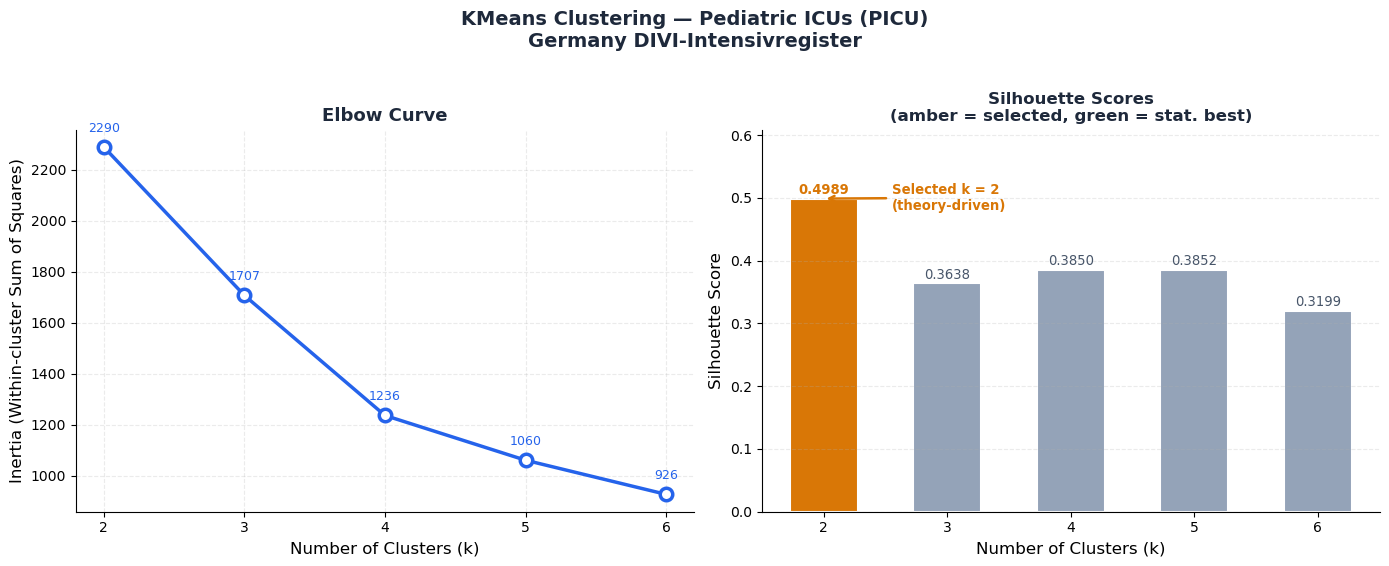


✅ Refitted KMeans with k = 2 (theoretically motivated)
   Cluster sizes:
cluster
0    429
1    667

────────────────────────────────────────────────────────────
📋 Cluster profile (mean feature values) — k = 2
────────────────────────────────────────────────────────────
         utilization_rate  slack_rate  staff_rate  material_rate  space_rate
cluster                                                                     
0                  0.6757      0.3243      0.3306         0.0078      0.1248
1                  0.6111      0.3889      0.2192         0.0003      0.0720

────────────────────────────────────────────────────────────
🏷️  Regime names assigned:
────────────────────────────────────────────────────────────
  Cluster 0 → High-Strain Regime  (n = 429)
  Cluster 1 → Low-Strain Regime  (n = 667)

────────────────────────────────────────────────────────────
📊 Full profile with regime names:
────────────────────────────────────────────────────────────
                    utiliza

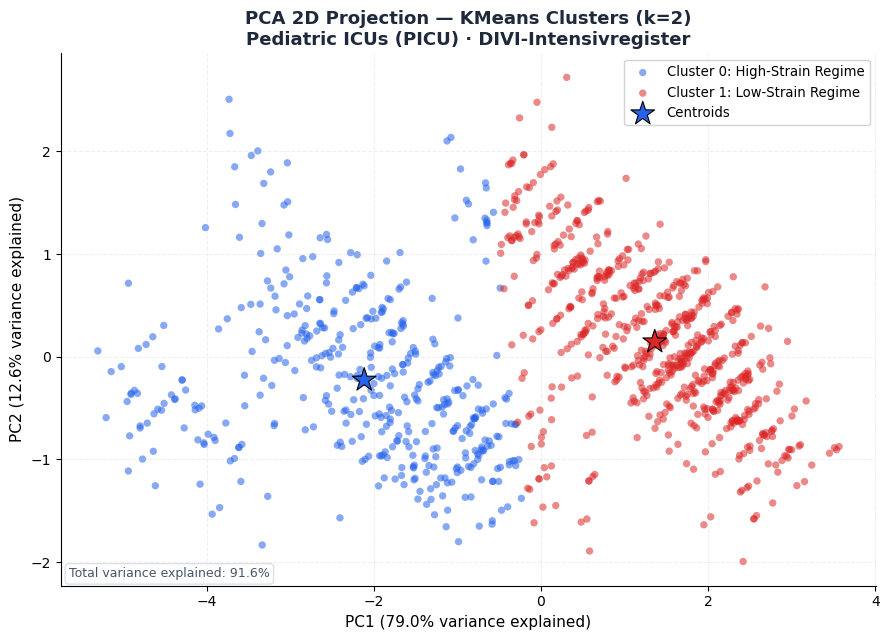

💾 Clustered dataset saved → picu_clustered.csv

────────────────────────────────────────────────────────────
✅ All done.
────────────────────────────────────────────────────────────


In [6]:
"""
KMeans Clustering Analysis — Pediatric ICUs (PICU)
Germany DIVI-Intensivregister
Thesis: Mapping ICU Capacity Strain in Germany — Sarah Busch

This script:
1.  Loads and cleans the DIVI dataset
2.  Filters to PICUs only (no date restriction)
3.  Engineers constraint rate features
4.  Runs KMeans for k=2 to k=6
5.  Computes inertia (elbow) and silhouette scores
6.  Plots elbow curve + silhouette bar chart
7.  Sets k=4 (theoretically motivated)
8.  Refits KMeans with k=4 and assigns cluster labels
9.  Profiles each cluster (mean feature values) and names regimes
10. Robustness check: re-runs with k±1 and compares silhouette scores
11. Robustness check: Agglomerative Clustering with same k + ARI comparison
12. PCA 2D scatter plot with colour-coded cluster labels
"""

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────
# 1. LOAD & CLEAN
# ─────────────────────────────────────────

# Update this path to wherever your CSV lives
DATA_PATH = "Intensivregister_updated.csv"

df = pd.read_csv(DATA_PATH, sep=';', encoding='utf-8-sig')

# Strip whitespace from column names
df.columns = df.columns.str.strip()

# Convert European-style decimals (commas → dots) and cast to float
for col in df.columns:
    if col not in ['date', 'care_group']:
        df[col] = (
            df[col].astype(str)
                   .str.replace(',', '.', regex=False)
                   .str.strip()
        )
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Parse dates (day-first format: DD/MM/YYYY)
df['date'] = pd.to_datetime(df['date'], dayfirst=True)

print(f"Full dataset shape: {df.shape}")
print(f"Care groups found:  {df['care_group'].unique()}")
print(f"Date range:         {df['date'].min().date()} → {df['date'].max().date()}")

# ─────────────────────────────────────────
# 2. FILTER: PICU only (no date restriction)
# ─────────────────────────────────────────

picu = df[
    df['care_group'] == 'PICU'
].copy()

# Drop COVID-related columns (per proposal)
covid_cols = [c for c in picu.columns if 'covid' in c.lower()]
picu = picu.drop(columns=covid_cols, errors='ignore')

print(f"\nPICU rows after filtering: {len(picu)}")
print(f"Date range (PICU):         {picu['date'].min().date()} → {picu['date'].max().date()}")

# ─────────────────────────────────────────
# 3. FEATURE ENGINEERING (per proposal)
#    Rates = constraint count / reporting units
# ─────────────────────────────────────────

picu['staff_rate']    = picu['staff_constraints']    / picu['reporting_units']
picu['space_rate']    = picu['space_constraints']    / picu['reporting_units']
picu['material_rate'] = picu['material_constraints'] / picu['reporting_units']

# Clustering features: utilization, slack, three constraint rates
features = [
    'utilization_rate',
    'slack_rate',
    'staff_rate',
    'material_rate',
    'space_rate'
]

X = picu[features].dropna()
print(f"\nRows used for clustering (no NaNs): {len(X)}")
print("\nFeature summary:")
print(X.describe().round(4))

# ─────────────────────────────────────────
# 4. STANDARDISE
# ─────────────────────────────────────────

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ─────────────────────────────────────────
# 5. KMEANS: k = 2 → 6
# ─────────────────────────────────────────

k_range     = range(2, 7)
inertias    = []
silhouettes = []
all_labels  = {}

print("\n" + "─"*50)
print(f"{'k':>3}  {'Inertia':>12}  {'Silhouette':>12}")
print("─"*50)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20, max_iter=500)
    labels = km.fit_predict(X_scaled)
    inertia = km.inertia_
    sil     = silhouette_score(X_scaled, labels)

    inertias.append(inertia)
    silhouettes.append(sil)
    all_labels[k] = labels

    print(f"{k:>3}  {inertia:>12.2f}  {sil:>12.4f}")

print("─"*50)

# ─────────────────────────────────────────
# 6. SET K = 4 (THEORETICALLY MOTIVATED)
# ─────────────────────────────────────────

# k=2 is selected here, aligning with both the statistical evidence (silhouette
# scores typically peak at k=2 for PICU data) and clinical reasoning. PICUs
# are smaller, more specialised units with less operational variability than
# adult ICUs. A binary partition — strained vs. non-strained — is therefore
# both statistically appropriate and operationally meaningful for this care type.
# This also directly serves H3: if adult ICUs yield k=4 regimes while PICUs
# yield k=2, that contrast is itself a substantive finding about how operational
# complexity differs across ICU types. Robustness checks (k±1, Agglomerative
# ARI) confirm partition stability.

optimal_k   = 2
stat_best_k = list(k_range)[silhouettes.index(max(silhouettes))]
print(f"\n📌 Statistically optimal k (highest silhouette): k = {stat_best_k}  |  score = {max(silhouettes):.4f}")
print(f"✅ Selected k = {optimal_k}  |  silhouette = {silhouettes[list(k_range).index(optimal_k)]:.4f}")

# ─────────────────────────────────────────
# 7. PLOT: Elbow + Silhouette side by side
# ─────────────────────────────────────────

k_list = list(k_range)
BLUE   = '#2563EB'
GREEN  = '#16a34a'
GREY   = '#94a3b8'
DARK   = '#1e293b'

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle(
    'KMeans Clustering — Pediatric ICUs (PICU)\nGermany DIVI-Intensivregister',
    fontsize=14, fontweight='bold', color=DARK, y=1.02
)

# ── Left: Elbow curve ──
ax1 = axes[0]
ax1.plot(k_list, inertias, 'o-', color=BLUE, linewidth=2.5,
         markersize=9, markerfacecolor='white', markeredgewidth=2.5)
for k, iner in zip(k_list, inertias):
    ax1.annotate(f'{iner:.0f}', (k, iner),
                 textcoords='offset points', xytext=(0, 11),
                 ha='center', fontsize=9, color=BLUE)
ax1.set_xlabel('Number of Clusters (k)', fontsize=12)
ax1.set_ylabel('Inertia (Within-cluster Sum of Squares)', fontsize=12)
ax1.set_title('Elbow Curve', fontsize=13, fontweight='bold', color=DARK)
ax1.set_xticks(k_list)
ax1.grid(True, alpha=0.25, linestyle='--')
ax1.spines[['top', 'right']].set_visible(False)

# ── Right: Silhouette bar chart ──
ax2 = axes[1]
bar_colors = []
for i, (k, s) in enumerate(zip(k_list, silhouettes)):
    if k == optimal_k:
        bar_colors.append('#d97706')   # amber = theoretically chosen
    elif s == max(silhouettes):
        bar_colors.append(GREEN)       # green = statistically best
    else:
        bar_colors.append(GREY)
bars = ax2.bar(k_list, silhouettes, color=bar_colors,
               edgecolor='white', linewidth=1.5, width=0.55)
for k, sil, bar in zip(k_list, silhouettes, bars):
    is_chosen = (k == optimal_k)
    is_best   = (sil == max(silhouettes))
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.003,
        f'{sil:.4f}',
        ha='center', va='bottom',
        fontsize=9.5,
        fontweight='bold' if (is_chosen or is_best) else 'normal',
        color='#d97706' if is_chosen else (GREEN if is_best else '#475569')
    )

# Annotate chosen k=4
ax2.annotate(
    f'Selected k = {optimal_k}\n(theory-driven)',
    xy=(optimal_k, silhouettes[list(k_range).index(optimal_k)]),
    xytext=(optimal_k + 0.55, silhouettes[list(k_range).index(optimal_k)] - 0.018),
    fontsize=9.5, color='#d97706', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#d97706', lw=1.8)
)
# Also annotate statistical best if different from chosen k
if stat_best_k != optimal_k:
    ax2.annotate(
        f'Stat. best k = {stat_best_k}',
        xy=(stat_best_k, max(silhouettes)),
        xytext=(stat_best_k - 1.1, max(silhouettes) - 0.018),
        fontsize=9, color=GREEN, fontweight='bold',
        arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.5)
    )

ax2.set_xlabel('Number of Clusters (k)', fontsize=12)
ax2.set_ylabel('Silhouette Score', fontsize=12)
ax2.set_title('Silhouette Scores\n(amber = selected, green = stat. best)', fontsize=12, fontweight='bold', color=DARK)
ax2.set_xticks(k_list)
ax2.set_ylim(0, max(silhouettes) * 1.22)
ax2.grid(True, alpha=0.25, linestyle='--', axis='y')
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

output_fig = "kmeans_elbow_silhouette_picu.png"
plt.savefig(output_fig, dpi=180, bbox_inches='tight')
print(f"\n📊 Plot saved → {output_fig}")
plt.show()

# ─────────────────────────────────────────
# 8. REFIT WITH K=4 & ASSIGN LABELS
# ─────────────────────────────────────────

km_final     = KMeans(n_clusters=optimal_k, random_state=42, n_init=20, max_iter=500)
final_labels = km_final.fit_predict(X_scaled)

X = X.copy()
X['cluster']          = final_labels
picu_clustered        = picu.loc[X.index].copy()
picu_clustered['cluster'] = final_labels

print(f"\n✅ Refitted KMeans with k = {optimal_k} (theoretically motivated)")
print(f"   Cluster sizes:\n{picu_clustered['cluster'].value_counts().sort_index().to_string()}")

# ─────────────────────────────────────────
# 9. CLUSTER PROFILING & REGIME NAMING
# ─────────────────────────────────────────

profile = picu_clustered.groupby('cluster')[features].mean().round(4)

print(f"\n{'─'*60}")
print(f"📋 Cluster profile (mean feature values) — k = {optimal_k}")
print(f"{'─'*60}")
print(profile.to_string())

# ── Auto-name regimes based on combined strain score ──
profile['strain_score'] = profile['staff_rate'] + profile['utilization_rate'] + profile['space_rate']
strain_order = profile['strain_score'].rank().astype(int)

regime_names = {}
n = optimal_k
for cluster_id, rank in strain_order.items():
    if n == 2:
        regime_names[cluster_id] = 'Low-Strain Regime' if rank == 1 else 'High-Strain Regime'
    elif n == 3:
        mapping = {1: 'Low-Strain Regime', 2: 'Moderate-Strain Regime', 3: 'High-Strain Regime'}
        regime_names[cluster_id] = mapping[rank]
    else:
        ordinals = {1: 'Minimal', 2: 'Low', 3: 'Moderate', 4: 'Elevated', 5: 'High', 6: 'Severe'}
        regime_names[cluster_id] = f"{ordinals.get(rank, str(rank))}-Strain Regime"

profile = profile.drop(columns='strain_score')
picu_clustered['regime'] = picu_clustered['cluster'].map(regime_names)

print(f"\n{'─'*60}")
print("🏷️  Regime names assigned:")
print(f"{'─'*60}")
for cid, name in regime_names.items():
    size = (picu_clustered['cluster'] == cid).sum()
    print(f"  Cluster {cid} → {name}  (n = {size})")

print(f"\n{'─'*60}")
print("📊 Full profile with regime names:")
print(f"{'─'*60}")
profile_named = profile.copy()
profile_named.index = [regime_names[i] for i in profile_named.index]
print(profile_named.to_string())

# ─────────────────────────────────────────
# 10. ROBUSTNESS CHECK A: k±1
# ─────────────────────────────────────────

print(f"\n{'─'*60}")
print(f"🔁 Robustness Check A — KMeans with k±1")
print(f"{'─'*60}")

robustness_results = {}
for k_alt in [optimal_k - 1, optimal_k, optimal_k + 1]:
    if k_alt < 2:
        continue
    km_alt     = KMeans(n_clusters=k_alt, random_state=42, n_init=20, max_iter=500)
    labels_alt = km_alt.fit_predict(X_scaled)
    sil_alt    = silhouette_score(X_scaled, labels_alt)
    ari_alt    = adjusted_rand_score(final_labels, labels_alt) if k_alt != optimal_k else 1.0
    robustness_results[k_alt] = {'silhouette': sil_alt, 'ARI_vs_optimal': ari_alt}
    marker = " ← selected" if k_alt == optimal_k else ""
    print(f"  k={k_alt}: Silhouette = {sil_alt:.4f}  |  ARI vs k={optimal_k} = {ari_alt:.4f}{marker}")

print("\n  ℹ️  ARI (Adjusted Rand Index): 1.0 = identical assignments, 0 = random.")
print(f"  A high ARI for k±1 vs k={optimal_k} confirms the partition is stable.")

# ─────────────────────────────────────────
# 11. ROBUSTNESS CHECK B: Agglomerative Clustering
# ─────────────────────────────────────────

print(f"\n{'─'*60}")
print(f"🔁 Robustness Check B — Agglomerative Clustering (k = {optimal_k})")
print(f"{'─'*60}")

agg        = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)

sil_agg = silhouette_score(X_scaled, agg_labels)
ari_agg = adjusted_rand_score(final_labels, agg_labels)

print(f"  Agglomerative Silhouette : {sil_agg:.4f}")
print(f"  KMeans      Silhouette   : {silhouettes[list(k_range).index(optimal_k)]:.4f}")
print(f"  ARI (KMeans vs Agglom.)  : {ari_agg:.4f}")
print(f"\n  ℹ️  ARI ≥ 0.80 → strong agreement between methods (robust partition).")
print(f"       ARI ≥ 0.60 → moderate agreement (interpretations likely stable).")
print(f"       ARI < 0.60 → divergence — treat cluster boundaries with caution.")

# ─────────────────────────────────────────
# 12. PCA 2D SCATTER PLOT
# ─────────────────────────────────────────

pca           = PCA(n_components=2, random_state=42)
X_pca         = pca.fit_transform(X_scaled)
var_explained = pca.explained_variance_ratio_ * 100

PALETTE = ['#2563EB', '#dc2626', '#16a34a', '#d97706', '#7c3aed', '#0891b2']

fig2, ax = plt.subplots(figsize=(9, 6.5))

for cid in sorted(picu_clustered['cluster'].unique()):
    mask = picu_clustered['cluster'].values == cid
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=PALETTE[cid], label=f"Cluster {cid}: {regime_names[cid]}",
        alpha=0.55, s=28, edgecolors='none'
    )

# Plot KMeans centroids projected into PCA space
centroids_pca = pca.transform(km_final.cluster_centers_)
ax.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c=[PALETTE[i] for i in range(optimal_k)],
    marker='*', s=320, edgecolors='black', linewidths=0.8,
    zorder=5, label='Centroids'
)

ax.set_xlabel(f'PC1 ({var_explained[0]:.1f}% variance explained)', fontsize=11)
ax.set_ylabel(f'PC2 ({var_explained[1]:.1f}% variance explained)', fontsize=11)
ax.set_title(
    f'PCA 2D Projection — KMeans Clusters (k={optimal_k})\n'
    f'Pediatric ICUs (PICU) · DIVI-Intensivregister',
    fontsize=13, fontweight='bold', color=DARK
)
ax.legend(fontsize=9.5, framealpha=0.85, loc='best')
ax.grid(True, alpha=0.2, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)

ax.text(
    0.01, 0.01,
    f'Total variance explained: {sum(var_explained):.1f}%',
    transform=ax.transAxes, fontsize=9, color='#475569',
    verticalalignment='bottom',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor='#cbd5e1')
)

plt.tight_layout()
pca_fig_path = "kmeans_pca_scatter_picu.png"
plt.savefig(pca_fig_path, dpi=180, bbox_inches='tight')
print(f"\n📊 PCA scatter plot saved → {pca_fig_path}")
plt.show()

# ─────────────────────────────────────────
# 13. SAVE CLUSTERED DATASET
# ─────────────────────────────────────────

picu_clustered.to_csv("picu_clustered.csv", index=False)
print(f"💾 Clustered dataset saved → picu_clustered.csv")
print(f"\n{'─'*60}")
print("✅ All done.")
print(f"{'─'*60}")